In [25]:
cd /Users/cl1704/PycharmProjects/embedding_dimension/BWM

/Users/cl1704/PycharmProjects/embedding_dimension/BWM


In [26]:
import pandas as pd
from matplotlib import gridspec
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib
import numpy as np
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import torch
import random
import string
import os
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, TensorDataset
from scipy.ndimage import gaussian_filter1d
from sklearn.decomposition import PCA
from iblatlas.regions import BrainRegions
br = BrainRegions()
import pandas as pd

from iblatlas.regions import BrainRegions
br = BrainRegions()
from scipy.sparse import save_npz, load_npz, csr_matrix

#task_id = int(os.environ['SLURM_ARRAY_TASK_ID'])

from bwm_functions import *


In [27]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import torch
import random
import string
import os
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, TensorDataset
from scipy.ndimage import gaussian_filter1d
from sklearn.decomposition import PCA
from iblatlas.regions import BrainRegions
br = BrainRegions()
from bwm_functions import *

In [28]:
def get_spike_counts_in_bins(spike_times, spike_clusters, intervals):
    # Check input
    assert intervals.ndim == 2
    assert intervals.shape[1] == 2
    assert np.all(np.diff(spike_times) >= 0), "Spike times need to be sorted"
    intervals_idx = np.searchsorted(spike_times, intervals)
    # For each neuron and each interval, the number of spikes in the interval.
    cluster_ids = np.unique(spike_clusters)
    n_neurons = len(cluster_ids)
    n_intervals = intervals.shape[0]
    counts = np.zeros((n_neurons, n_intervals), dtype=np.uint32)
    for j in range(n_intervals):
        i0, i1 = intervals_idx[j, :]
        # Count the number of spikes in the window, for each neuron.
        x = np.bincount(spike_clusters[i0:i1], minlength=cluster_ids.max() + 1)
        counts[:, j] = x[cluster_ids]
    return counts, cluster_ids

In [29]:
def restrict_to_region(spikes,cluster_df,regions):
    # within_region_cluster_ids = cluster_df[cluster_df.cosmos==cosmos].cluster_id.values
    # all_cluster_ids = spikes['clusters']
   # idx = np.argwhere(cluster_df['cosmos'][spikes['clusters']].isin(cosmos))[:,0]
    idx = [i for i, x in enumerate(cluster_df['cosmos'][spikes['clusters']]) if x in regions]
    spike_times = spikes['times'][idx]
    spike_clusters= spikes['clusters'][idx]
    return spike_clusters, spike_times

In [30]:
def df_2_repsonse_matrix(df, conditions):
    response_matrix = []
    condition_matrix = []
    for pseudo_trial in range(500):
        # Sample with replacement from each condition
        sub_df = df.groupby(conditions).sample(frac=1.0, replace=True)
        # Compute mean response for each condition
        mean_df = sub_df.groupby(conditions).response.apply(lambda x: np.mean(np.stack(x), axis=0)).reset_index()
        # Append
        response_matrix.append(np.stack(mean_df.response.values))
        condition_matrix.append(mean_df[conditions].values)
    response_matrix = np.stack(response_matrix, axis=0)
    condition_matrix = np.stack(condition_matrix, axis=0)
    return response_matrix, condition_matrix

In [31]:
def get_aligned_response_matrix(spikes,clusters, trials, event,conditions, stride=.01, step=.01, n_steps=100,sigma = 5,threshold = 5,min_trials_per_condition = 10,regions=None):

    event_times = trials[event]
    n_trials = len(event_times)

    # Get spike counts in bins aligned to event times.
    intervals = []
    for trial in range(n_trials):
        start = event_times[trial] - .05
        for _ in range (n_steps):
            intervals.append([start, start + stride])
            start += step
    intervals = np.stack(intervals)
    spike_clusters,spike_times = restrict_to_region(spikes,clusters,regions)
    spike_count, cluster_id = get_spike_counts_in_bins(spike_times, spike_clusters,intervals= intervals)

    # Reshape spike_counts in 3D array
    spike_count = spike_count.T.reshape(n_trials,n_steps,-1)

    response_matrix = np.zeros(spike_count.shape)
    for neuron in range(spike_count.shape[2]):
        for trial in range(spike_count.shape[0]):
            response_matrix[trial,:,neuron] = gaussian_filter1d(spike_count[trial,:,neuron]/stride,sigma = sigma)

    rows = []
    contrasts = np.nan_to_num(-trials['contrastLeft'], copy=True, nan=1.0) * np.nan_to_num(
    trials['contrastRight'], copy=True, nan=1.0)
    for trial in range(1,n_trials):
        rows.append({'trial':trial,
                     'choice': trials['choice'][trial],
                     'prev_choice': trials['choice'][trial-1],
                     'reward': trials['feedbackType'][trial],
                     'prev_reward': trials['feedbackType'][trial-1],
                     'contrast': contrasts[trial],
                     'block': trials['probabilityLeft'][trial],
                     'side': np.sign(contrasts[trial]),
                     'prev_side': np.sign(contrasts[trial-1]),
                     'response': response_matrix[trial,:,:],})

    # Remove inactive neurons
    df = pd.DataFrame(rows)
    # Restrict to conditions that have a minimum number of trials
    df = df[df.groupby(conditions)[conditions].transform('size') >= min_trials_per_condition]
    response_matrix_train, condition_matrix_train = df_2_repsonse_matrix(df, conditions)
    return response_matrix_train, condition_matrix_train#, response_matrix_test, condition_matrix_test

In [32]:
directory_path = 'Data'
all_items = os.listdir(directory_path)
# Filter the list to include only folders (directories)
eids = [item for item in all_items if os.path.isdir(os.path.join(directory_path, item))]

# Hyperparameters
dim = 10
sample_size = 50
sigma = 5
n_steps = 100
threshold = .01
min_trials_per_condition = 50
conditions = ['side']
event = "stimOn_times"
regions = ["MRN"]

In [33]:
# shape n_pseudo x n_conditions x time x n
responses = []
for i in range(100):
    eid = eids[i]
    print(i)
    full_path_to_random_folder = os.path.join(directory_path, eid)
    print(f"Randomly selected eid: {full_path_to_random_folder}")
    try:
        clusters = pd.read_pickle(full_path_to_random_folder + '/clusters.pkl')
        clusters['cosmos'] = br.id2acronym(clusters['atlas_id'], mapping="Beryl")
        spikes = pd.read_pickle(full_path_to_random_folder + '/spikes.pkl')
        trials = pd.read_pickle(full_path_to_random_folder + '/trials.pkl')
        counts_series = clusters.groupby('cosmos').size()
        print(counts_series)
        response_matrix_train, condition_matrix_train = get_aligned_response_matrix(
            spikes, clusters, trials, event, conditions,
            stride=.005,
            step=.005,
            n_steps=n_steps,
            sigma=sigma,
            threshold=threshold,
            min_trials_per_condition=min_trials_per_condition,regions= regions)

        # Restrict to active units
        restriction = np.logical_and(np.mean(response_matrix_train, axis=(0, 1, 2)) > 1,
                                     np.mean(response_matrix_train, axis=(0, 1, 2)) > 1)
        response_matrix_train = response_matrix_train[
            :, :, :, restriction]



        n_conditions = response_matrix_train.shape[1]
        # Z-score single neuron responses
        response_matrix_train = (response_matrix_train - np.mean(response_matrix_train, axis=(0, 1, 2),
                                                                 keepdims=True)) / np.std(response_matrix_train,
                                                                                          axis=(0, 1, 2),
                                                                                          keepdims=True)
        responses.append(response_matrix_train)
    except:
        print("Failed")
        continue

0
Randomly selected eid: Data/b52182e7-39f6-4914-9717-136db589706e
cosmos
APN      133
CA1      111
CA3       94
DG        66
MRN       25
ProS       2
RN        10
TR         2
VISam     60
VISpm     87
root      29
void       1
dtype: int64
1
Randomly selected eid: Data/9fc31d79-b56f-46d0-92a0-e9563caf4a7a
cosmos
DG        3
LH        3
MD        5
MH       16
PCN       1
RSPv    139
VM        3
root      2
dtype: int64
Failed
2
Randomly selected eid: Data/cc45c568-c3b9-4f74-836e-c87762e898c8
cosmos
ACAd    135
ACAv    103
APN     153
CA3      16
Eth      43
IG       27
LSr     132
NOT       1
PoT      32
SNr      19
SPF      11
ZI       53
root    103
dtype: int64
Failed
3
Randomly selected eid: Data/e6de6c35-1508-4471-b7c3-f12a5c7a6d39
cosmos
CUN      29
IC       26
PB       74
PRNc    148
RM        3
root    126
dtype: int64
Failed
4
Randomly selected eid: Data/fece187f-b47f-4870-a1d6-619afe942a7d
cosmos
IRN        125
PAG         41
PRNc       235
RT         148
SSp-bfd     59
VI

In [34]:
device = 'cpu'
class Net(torch.nn.Module):
    def __init__(self, n, alpha=.2, sigma_rec=0., sigma_in=0.2, input_size=6, output_size=2, dale=False,
                 lambda_std=0., base_in=0., beta=10):
        super(Net, self).__init__()
        self.alpha = torch.tensor(alpha)
        self.sigma_rec = torch.tensor(sigma_rec)
        self.sigma_in = torch.tensor(sigma_in)
        self.n = n
        self.input_size = input_size
        self.output_size = output_size
        self.dale = dale
        self.lambda_std = lambda_std
        self.base_in = base_in

        self.beta = beta
        self.activation = torch.nn.Softplus(beta=self.beta)
        # self.activation = torch.nn.ReLU()

        # Connectivity
        self.recurrent_layer = nn.Linear(self.n, self.n, bias=True)
        #self.recurrent_layer.weight.data.fill_diagonal_(0)

        self.recurrent_layer.bias.data.normal_(mean=0.2, std=0).to(device=device)
        self.recurrent_layer.bias.requires_grad = True

        self.input_layer = nn.Linear(self.input_size, self.n, bias=True)
        self.input_layer.bias.data.normal_(mean=self.base_in, std=0.).to(device=device)
        self.input_layer.bias.requires_grad = False
        # self.input_layer.weight.data = torch.where(torch.rand_like(self.input_layer.weight.data)> 0.5, -self.input_layer.weight.data, self.input_layer.weight.data)

        self.output_layer = nn.Linear(self.n, self.output_size, bias=True)
        self.output_layer.bias.data.normal_(mean=-self.base_in, std=0).to(device=device)
        self.output_layer.bias.requires_grad = False

    # Dynamics
    def forward(self, u, training=False):
        t = u.shape[1]
        states = torch.zeros(u.shape[0], 1, self.n, device=device)

        batch_size = states.shape[0]
        input_noise = torch.sqrt(2 / self.alpha * self.sigma_in ** 2) * torch.empty(batch_size, t,
                                                                                    self.input_size).normal_(mean=0,
                                                                                                             std=1).to(
            device=device)

        recurrent_noise = self.sigma_rec * torch.empty(batch_size, t, self.n).normal_(
            mean=0,std=1).to(device=device)
        inputs = self.input_layer(u + input_noise)
        for i in range(t - 1):
            state_new = (1 - self.alpha) * states[:, i, :] + self.alpha * (
                self.activation(self.recurrent_layer(states[:, i, :]) + inputs[:, i, :] + states[:,i,:] * recurrent_noise[:,i,:]))
            states = torch.cat((states, state_new.unsqueeze_(1)), 1)

        return states





    def plane_parallelism(self, x, u):
        h = self.recurrent_layer(x) + self.input_layer(u)
        h = h - torch.mean(h, dim=(0, 1), keepdim=True)

        z = x - torch.mean(x, dim=[0, 1], keepdim=True)
       # dist = torch.var(z @ self.recurrent_layer.weight.t()) / torch.var(h, dim=(0, 1))
        d =  h / torch.linalg.norm(self.recurrent_layer.weight,dim=1)
        d = d - torch.mean(d, dim=(0, 1), keepdim=True)
        beta = torch.sum(h * z, dim=(0, 1)) / torch.sum(h ** 2, dim=(0, 1))
        #beta = torch.var(x,dim=(0,1))/ torch.var(h, dim=(0, 1))
        return torch.mean(beta), torch.std(beta),beta


    def flow_parallelism(self,x,u):
        hpoints = self.recurrent_layer(x) + self.input_layer(u)
        flow_field = -x + self.activation(hpoints)
        curvature = (flow_field @ self.recurrent_layer.weight.t())**2 * (torch.clamp(torch.exp(100*hpoints.detach()),max = 1e6)/(1+torch.clamp(torch.exp(100*hpoints.detach()),max = 1e6))**2)
        dist = torch.var(x, dim=(0, 1)) /  torch.mean(curvature,dim = (0,1))
        return  torch.mean(dist), torch.std(dist)

    def J(self, y):
        n = y.shape[2]
        a = self.recurrent_layer.weight
        eye = torch.eye(n).unsqueeze(dim=(0)).repeat(y.shape[0], y.shape[1], 1, 1)
        b = torch.exp(self.beta * (self.recurrent_layer(y))) / (
                1 + torch.exp(self.beta * (self.recurrent_layer(y))))
        c = -eye + b.unsqueeze(dim=3).repeat((1, 1, 1, n)) * a
        return c

    def fit(self, u, z, mask,target_beta,target_fve, conditions, dim, pca_target_1=0,
            pca_target_2=0,
            lambda_pca_1=0,
            lambda_pca_2=0,
            gain_target=0,
            lambda_gain_mean=0,
            lambda_gain_std=0,
            kmeans_target = 0,
            lambda_kmeans = 0,
            epochs=10000, lr=.01, verbose=False, weight_decay=0):

        my_dataset = TensorDataset(u, z, mask)  # create your datset
        my_dataloader = DataLoader(my_dataset, batch_size=64, shuffle=True)

        optimizer = torch.optim.Adam(self.parameters(), lr=lr, weight_decay=weight_decay)
        epoch = 0
        # mse_z=1
        # lds = LDS(n=dim, hidden_n = 5).to(device)

        while epoch < epochs:

            # Fit LDS model to full dataset after z-scoring
            #  x = self.forward(u)
            # x = (x - torch.mean(x, dim=[0, 1])) / (torch.std(x, dim=[0, 1]) + 1e-4)
            # lds.fit(u, x.detach())
            # lds_error_mean, lds_error_std = self.linear_error(lds.output_layer(lds(u)).detach(), x)

            # pca = PCA(n_components=dim).fit(x.reshape(-1, x.shape[2]).detach().numpy())
            #  pcs = torch.tensor(pca.components_[:dim, :]).float()

            for batch_idx, (u_batch, z_batch, mask_batch) in enumerate(my_dataloader):

                optimizer.zero_grad()

                # Z-score batch data
                x_batch = self.forward(u_batch, training=True)
                x_batch_centered = (x_batch - torch.mean(x_batch, dim=[0, 1])) / (torch.std(x_batch, dim=[0, 1]) + 1e-4)

                # K Means


                # PCA
                eigs = torch.sort(torch.real(
                    torch.linalg.eigvals(torch.cov(x_batch_centered.reshape(-1, x_batch_centered.shape[2]).t()))),
                                  descending=True)[0]
                fve = eigs/torch.sum(eigs)
                #pca_error = torch.sum(eigs[dim:]) / torch.sum(eigs)

                gain_mean, gain_std, beta = self.plane_parallelism(x_batch, u_batch)



                loss = lambda_gain_mean * torch.nn.MSELoss(reduction='mean')(beta, target_beta)+\
                    lambda_pca_1 * torch.nn.MSELoss(reduction='mean')(fve, target_fve)


                loss.backward()
                optimizer.step()
                #self.recurrent_layer.weight.data.fill_diagonal_(0)
                self.recurrent_layer.bias.data = torch.nn.ReLU()(self.recurrent_layer.bias.data)
                #self.input_layer.bias.data = torch.nn.ReLU()(self.input_layer.bias.data)
                epoch += 1
                if verbose:
                    if epoch % 50 == 0:
                        x = self.forward(u)
                        print('Epoch: {}/{}.............'.format(epoch, epochs), end=' ')
                        print("loss: {:.4f}".format(loss.item()))

                    # print("lds: {:.4f}".format(self.linear_error(linear_prediction,x_batch).item()))


In [35]:
cd /Users/cl1704/PycharmProjects/embedding_dimension/RNN

/Users/cl1704/PycharmProjects/embedding_dimension/RNN


In [36]:




import torch
from Experiment_10.ParametricWMTask import generate_trials

In [37]:
target_beta =np.mean(np.std(response_matrix_train, axis=0), axis=(0, 1))
pca = PCA().fit(np.mean(response_matrix_train, axis=0).reshape(-1,response_matrix_train.shape[3]))
target_fve = pca.explained_variance_ratio_
u, z, mask, conditions = generate_trials(n_trials=1,n_conditions = 25)


import numpy as np
import statsmodels.api as sm
import pandas as pd
#
net = Net(n=response_matrix_train.shape[3], input_size=u.shape[2],output_size=u.shape[2],
          dale=False,
          sigma_in=0.,
          sigma_rec = 0.,
          base_in=0,
          lambda_std=0.5,
          beta=
          20)


# Fit 4
dim = 4
net.fit(u,
        z,
        mask,
        torch.tensor(target_beta).float(),
        torch.tensor(target_fve).float(),
        lr=.001,
        epochs=500,
        conditions=conditions,
        verbose=True,
        dim=dim,
        weight_decay=0.001,
        pca_target_1 = .1,
        pca_target_2=0,
        gain_target=.75,
        kmeans_target = 0.,
        lambda_kmeans = 0,
        lambda_gain_mean=1,
        lambda_gain_std=.1,
        lambda_pca_1=1,
        lambda_pca_2=1,
                            )

Epoch: 50/500............. loss: 0.0012
Epoch: 100/500............. loss: 0.0005
Epoch: 150/500............. loss: 0.0004
Epoch: 200/500............. loss: 0.0003
Epoch: 250/500............. loss: 0.0003


KeyboardInterrupt: 

In [38]:
net.sigma_rec = 0
x = net(u).detach()
h = net.recurrent_layer(x) + net.input_layer(u)
h = h - torch.mean(h, dim=(0, 1), keepdim=True)

z = x - torch.mean(x, dim=[0, 1], keepdim=True)
# dist = torch.var(z @ self.recurrent_layer.weight.t()) / torch.var(h, dim=(0, 1))

beta = torch.sum(h * z, dim=(0, 1)) / torch.sum(h ** 2, dim=(0, 1))

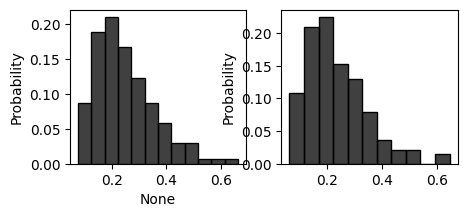

In [43]:


fig = plt.figure(figsize=(5, 2))
from scipy.spatial import ConvexHull

gs = gridspec.GridSpec(1, 2)
ax0 = fig.add_subplot(gs[0, 0])
ax1 = fig.add_subplot(gs[0, 1])
sns.histplot(x = beta.detach(),ax=ax0,color='black',stat = 'probability')
sns.histplot(x = target_beta,ax=ax1,color='black',stat = 'probability')
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.set_xlabel('')
#ax.set_xlim(.2,1)

ax.xaxis.set_tick_params(labelsize=7, bottom=True)
ax.yaxis.set_tick_params(labelsize=6, left=True)
ax.axes.get_yaxis().set_visible(False)
plt.savefig('Figures/Figure_1_d.jpg',
            format='jpeg',

            dpi=450,
            bbox_inches='tight', transparent=True)

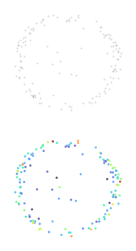

In [49]:
                                                  ####################################################################
#################### CLUSTERING PLOT ###############################
####################################################################
from sklearn.manifold import TSNE
net.sigma_rec = 0
x = net(u).detach()
h = net.recurrent_layer(x) + net.input_layer(u)
h = h - torch.mean(h, dim=(0, 1), keepdim=True)

z = x - torch.mean(x, dim=[0, 1], keepdim=True)
# dist = torch.var(z @ self.recurrent_layer.weight.t()) / torch.var(h, dim=(0, 1))

beta = torch.sum(h * z, dim=(0, 1)) / torch.sum(h ** 2, dim=(0, 1))


x = (x - torch.mean(x,dim=(0,1)))/ torch.std(x,dim=(0,1))
#x = x  + 2*(2*torch.rand_like(x)-1)
x = x.numpy()

x_proj  = PCA(n_components = 2).fit_transform(x.reshape(-1,x.shape[2]).T)
fig = plt.figure(figsize=(1.5,3))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(2,1,wspace = .3)
ax0=fig.add_subplot(gs[0,0])
ax1=fig.add_subplot(gs[1,0])
sns.scatterplot(x = x_proj[:,0],y = x_proj[:,1],s=2,ax=ax0,color='gray',alpha = .25,legend = False)
#sns.kdeplot(x = x_proj[:,0],y = x_proj[:,1],ax=ax0,color='gray',fill = True,legend = False,levels = 20,alpha = .5)

sns.scatterplot(x = x_proj[:,0],y = x_proj[:,1],ax=ax1,s=3,hue = torch.abs(beta).detach(),alpha = .75,legend = False,palette = 'turbo')
for ax in [ax0,ax1]:
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.axes.get_xaxis().set_visible(False)
    ax.axes.get_yaxis().set_visible(False)
plt.savefig('Figures/Figure_1_.jpg')


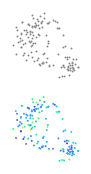

In [54]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.manifold import TSNE
fig = plt.figure(figsize=(1.5,2))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(2,1)
ax0=fig.add_subplot(gs[0,0])
ax1=fig.add_subplot(gs[1,0])

responses = np.mean(response_matrix_train, axis=0).reshape(-1,response_matrix_train.shape[3])
# kmeans = KMeans(n_clusters=10).fit(responses.T)
#
pca = TSNE(n_components =2,perplexity = 50)
#
x_proj = pca.fit_transform(responses.T)
sns.scatterplot(x=x_proj[:,0], y=x_proj[:,1],s = 2,ax=ax0,legend = False,alpha = 1,color='gray')
#sns.kdeplot(x=x_proj[:,0], y=x_proj[:,1],ax=ax0,legend = False,color='gray',fill=True,levels = 20)


# pca = PCA(n_components = 3)
# pca.fit(responses[:,data<.2].T)
#x_proj = pca.transform(responses.T)
sns.scatterplot(x=x_proj[:,0], y=x_proj[:,1],s=2,ax=ax1,legend = False,lw = 0,alpha = 1,hue = beta.detach(),palette = 'turbo',hue_norm = (0,1))


#ax2.tricontourf(x_proj[:,0], x_proj[:,1], data, levels=10, cmap='turbo',alpha = .6)
# responses = np.mean(response_matrix_train, axis=0).reshape(-1,response_matrix_train.shape[3])
# responses = responses[:,data<.2]
# pca = PCA(n_components = 3)
# pca.fit(responses.T)
# x_proj = pca.transform(responses.T)
# sns.scatterplot(x=x_proj[:,0], y=x_proj[:,1],s=8,ax=ax1,legend = False,lw = 0,alpha = .5)

for ax in [ax0,ax1]:
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.axes.get_xaxis().set_visible(False)
    ax.axes.get_yaxis().set_visible(False)
    ax.set_aspect('equal')
plt.savefig('Figures/Figure_1_b.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)
